In [1]:
import sys; sys.path.append("..")       # so the notebook can import app/
import pandas as pd, matplotlib.pyplot as plt
from app import db, profiling

con = db.connect()
df = profiling.add_flags(profiling.load_versions(con))
df[["filename", "label", "file_type", "status", "language", "effective_at", "word_count"]]

,filename,label,file_type,status,language,effective_at,word_count
0,architecture_v1.md,v1,md,ok,en,2026-01-10,30
1,architecture_v2.md,v2,md,ok,en,2026-02-15,35
2,architecture_v3.md,v3,md,ok,en,2026-03-20,34
3,broken_report.pdf,v1,pdf,failed,unknown,NaN,0
4,decisions.md,v1,md,ok,en,2026-02-01,33
5,decisions_copy.md,v1,md,ok,en,2026-02-01,33
6,empty_notes.md,v1,md,empty,unknown,NaN,0
7,meeting_2026_03.md,v1,md,ok,en,2026-03-05,30
8,meeting_2026_03_final.md,v1,md,ok,en,2026-03-05,30
9,requirements_v2.docx,v2,docx,ok,en,2026-02-20,27


status
ok        10
failed     1
empty      1
Name: count, dtype: int64 

Missing metadata (%):
doc_status      66.7
effective_at    25.0
author          83.3
dtype: float64


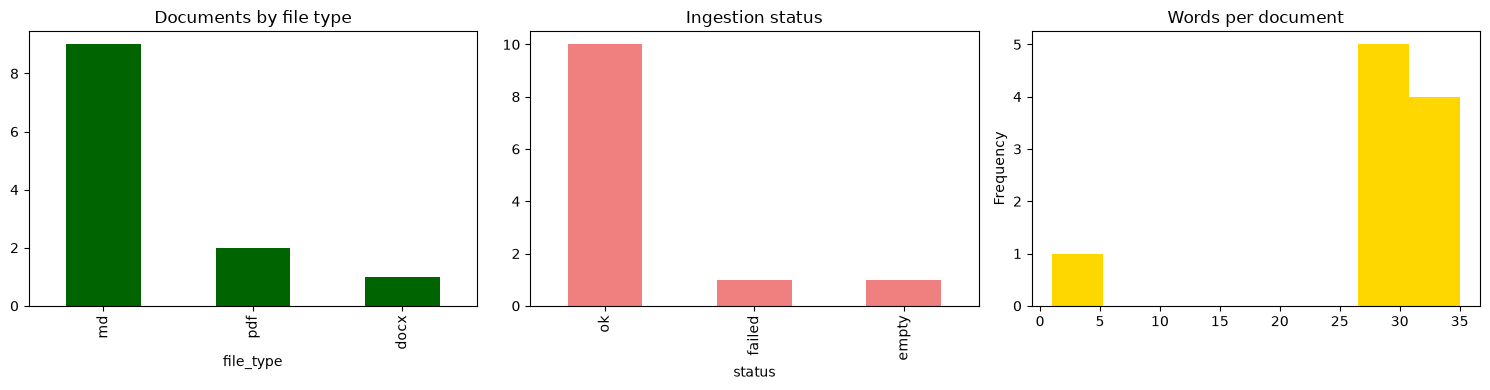

In [8]:
# Cell 2
print(df["status"].value_counts(), "\n")
print("Missing metadata (%):")
print((df[["doc_status", "effective_at", "author"]].isna().mean() * 100).round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["file_type"].value_counts().plot.bar(ax=ax[0], title="Documents by file type",color="darkgreen")
df["status"].value_counts().plot.bar(ax=ax[1], title="Ingestion status",color="lightcoral")
df.loc[df.status == "ok", "word_count"].plot.hist(ax=ax[2], bins=8, title="Words per document",color="gold")
plt.tight_layout(); plt.show()

status
ok        10
failed     1
empty      1
Name: count, dtype: int64 

Missing metadata (%):
doc_status      66.7
effective_at    25.0
author          83.3
dtype: float64


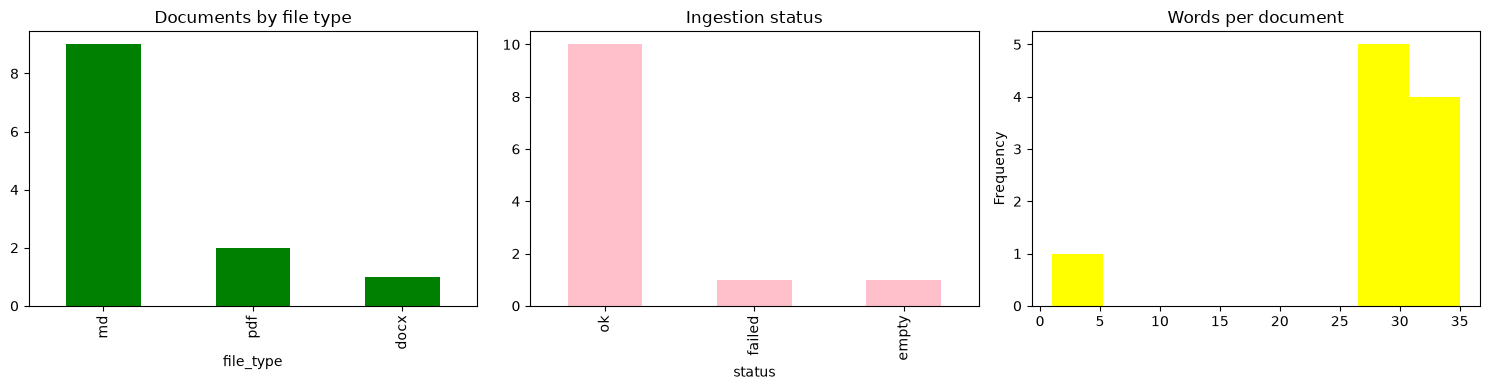

In [7]:
# Cell 2
print(df["status"].value_counts(), "\n")
print("Missing metadata (%):")
print((df[["doc_status", "effective_at", "author"]].isna().mean() * 100).round(1))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df["file_type"].value_counts().plot.bar(ax=ax[0], title="Documents by file type", color="green")
df["status"].value_counts().plot.bar(ax=ax[1], title="Ingestion status",color="pink")
df.loc[df.status == "ok", "word_count"].plot.hist(ax=ax[2], bins=8, title="Words per document",color="yellow")
plt.tight_layout(); plt.show()

In [4]:
# Cell 3: what did the quality checks find?
print("Exact duplicates:", profiling.find_exact_duplicates(df))
pd.DataFrame(profiling.find_near_duplicates(df), columns=["file_a", "file_b", "similarity"])

Exact duplicates: [['decisions.md', 'decisions_copy.md']]


,file_a,file_b,similarity
0,meeting_2026_03.md,meeting_2026_03_final.md,0.943


In [5]:
# Cell 4: flags persisted in the database
pd.read_sql("""SELECT v.filename, q.flag_type FROM quality_flags q
               JOIN document_versions v USING(version_id)""", con)

,filename,flag_type
0,broken_report.pdf,flag_failed_or_empty
1,empty_notes.md,flag_failed_or_empty
2,requirements_v2.docx,flag_very_short
3,short_note.md,flag_very_short
4,short_note.md,flag_missing_date
5,test_report_v1.pdf,flag_very_short
